In [ ]:
!pip -q install librosa soundfile scikit-learn seaborn joblib kaggle

In [ ]:
import os
import glob
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import soundfile as sf
import joblib
import tensorflow as tf

from pathlib import Path
from IPython.display import Audio, display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import files

uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise ValueError("Please upload the file named kaggle.json")

os.makedirs("/root/.kaggle", exist_ok=True)

with open("/root/.kaggle/kaggle.json", "wb") as f:
    f.write(uploaded["kaggle.json"])

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured.")

Saving kaggle.json to kaggle.json
Kaggle API configured.


In [ ]:
!kaggle kernels pull ddevvedd/gtzan

Source code downloaded to /content/gtzan.ipynb


In [ ]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.2/140.2 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 290.9/290.9 kB 25.7 MB/s eta 0:00:00


In [ ]:
!kaggle datasets download -d andradaolteanu/gtzan-dataset-music-genre-classification -p /content/gtzan --unzip

Dataset URL: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
License(s): other
100% 1.21G/1.21G [00:31<00:00, 41.3MB/s]



In [ ]:
search_roots = [
    "/content/gtzan",
    "/content/gtzan/Data",
    "/content/gtzan/genres"
]

audio_files = []

for root in search_roots:
    if os.path.exists(root):
        audio_files.extend(
            glob.glob(os.path.join(root, "**", "*.wav"), recursive=True)
        )

audio_files = sorted(set(audio_files))

if not audio_files:
    raise FileNotFoundError(
        "No WAV files found. Check the Kaggle download and extracted folders."
    )

print("Total WAV files:", len(audio_files))
print("Example paths:")
for path in audio_files[:5]:
    print(path)

Total WAV files: 1000
Example paths:
/content/gtzan/Data/genres_original/blues/blues.00000.wav
/content/gtzan/Data/genres_original/blues/blues.00001.wav
/content/gtzan/Data/genres_original/blues/blues.00002.wav
/content/gtzan/Data/genres_original/blues/blues.00003.wav
/content/gtzan/Data/genres_original/blues/blues.00004.wav


In [ ]:
genres = [
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock"
]

records = []

for path in audio_files:
    parent = os.path.basename(os.path.dirname(path)).lower()

    if parent in genres:
        records.append({
            "filepath": path,
            "genre": parent,
            "track_id": os.path.basename(path)
        })

df = pd.DataFrame(records)

print("Recognized audio tracks:", len(df))
print("\nGenre distribution:")
print(df["genre"].value_counts().sort_index())

if len(df) == 0:
    raise ValueError(
        "Genre folders were not recognized. Inspect the example paths from Cell 4."
    )

Recognized audio tracks: 1000

Genre distribution:
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


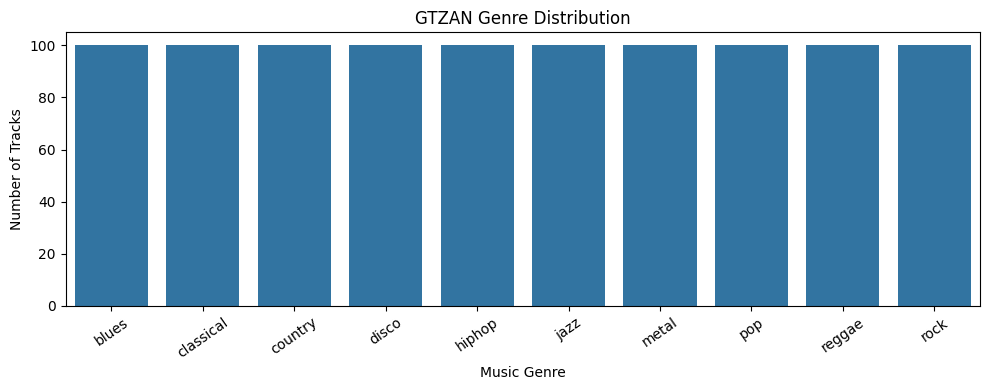

In [ ]:
plt.figure(figsize=(10, 4))

sns.countplot(
    data=df,
    x="genre",
    order=genres
)

plt.title("GTZAN Genre Distribution")
plt.xlabel("Music Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [ ]:
sample = df.iloc[0]

print("Genre:", sample["genre"])
print("File:", sample["filepath"])

y, sr = librosa.load(sample["filepath"], sr=22050, mono=True)

display(Audio(y, rate=sr))

Genre: blues
File: /content/gtzan/Data/genres_original/blues/blues.00000.wav


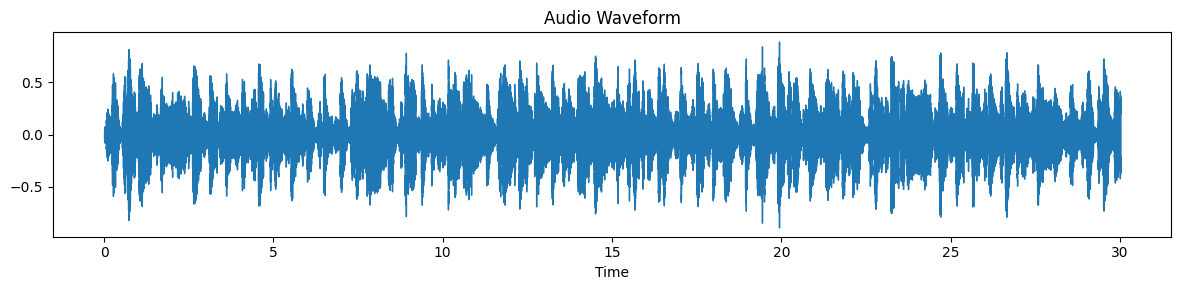

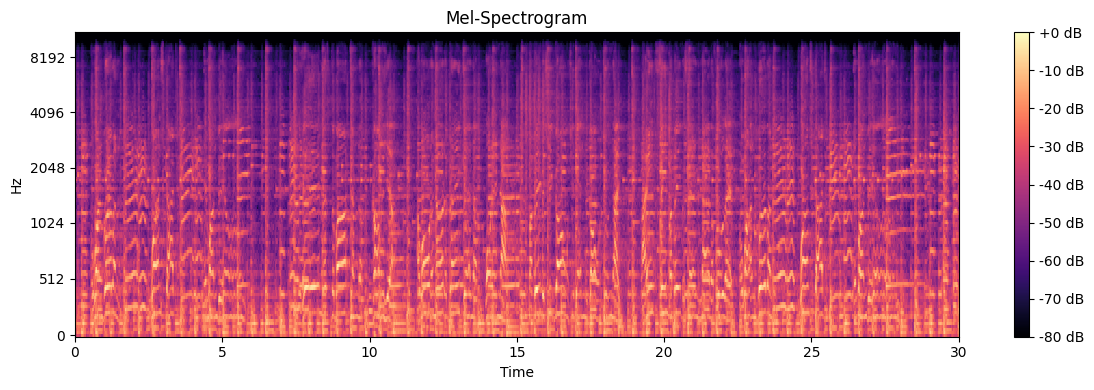

In [ ]:
plt.figure(figsize=(12, 3))
librosa.display.waveshow(y, sr=sr)
plt.title("Audio Waveform")
plt.tight_layout()
plt.show()

S = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

S_db = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel-Spectrogram")
plt.tight_layout()
plt.show()

In [ ]:
df = df.reset_index(drop=True)

encoder = LabelEncoder()
df["label"] = encoder.fit_transform(df["genre"])

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Train tracks:", len(train_df))
print("Validation tracks:", len(val_df))
print("Test tracks:", len(test_df))
print("Genres:", list(encoder.classes_))

assert set(train_df["filepath"]).isdisjoint(val_df["filepath"])
assert set(train_df["filepath"]).isdisjoint(test_df["filepath"])
assert set(val_df["filepath"]).isdisjoint(test_df["filepath"])

print("All checks passed: no overlapping tracks.")

Train tracks: 700
Validation tracks: 150
Test tracks: 150
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
All checks passed: no overlapping tracks.


In [ ]:
SR = 22050
DURATION = 30
SAMPLES = SR * DURATION

def load_audio(path):
    audio, sr = librosa.load(
        path,
        sr=SR,
        mono=True,
        duration=DURATION
    )

    if len(audio) < SAMPLES:
        audio = np.pad(audio, (0, SAMPLES - len(audio)))
    else:
        audio = audio[:SAMPLES]

    return audio, sr


def extract_features(path):
    audio, sr = load_audio(path)
    features = []

    # MFCCs: mean and standard deviation
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=20, n_fft=2048, hop_length=512
    )
    features.extend(np.mean(mfcc, axis=1))
    features.extend(np.std(mfcc, axis=1))

    # Chroma
    chroma = librosa.feature.chroma_stft(
        y=audio, sr=sr, n_fft=2048, hop_length=512
    )
    features.extend(np.mean(chroma, axis=1))
    features.extend(np.std(chroma, axis=1))

    # Spectral features
    spectral_centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)
    zero_crossing = librosa.feature.zero_crossing_rate(audio)
    rms = librosa.feature.rms(y=audio)

    for feature in [
        spectral_centroid,
        spectral_bandwidth,
        spectral_rolloff,
        zero_crossing,
        rms
    ]:
        features.extend([
            np.mean(feature),
            np.std(feature)
        ])

    return np.asarray(features, dtype=np.float32)

In [ ]:
from tqdm.auto import tqdm

feature_cache = {}

for path in tqdm(df["filepath"], desc="Extracting audio features"):
    try:
        feature_cache[path] = extract_features(path)
    except Exception as e:
        print("Skipping unreadable audio:", path, str(e))

valid_paths = set(feature_cache.keys())
df_valid = df[df["filepath"].isin(valid_paths)].copy()

train_df = train_df[train_df["filepath"].isin(valid_paths)].copy()
val_df = val_df[val_df["filepath"].isin(valid_paths)].copy()
test_df = test_df[test_df["filepath"].isin(valid_paths)].copy()

X_train = np.stack([feature_cache[p] for p in train_df["filepath"]])
X_val = np.stack([feature_cache[p] for p in val_df["filepath"]])
X_test = np.stack([feature_cache[p] for p in test_df["filepath"]])

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Feature matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

Extracting audio features:   0%|          | 0/1000 [00:00<?, ?it/s]

Skipping unreadable audio: /content/gtzan/Data/genres_original/jazz/jazz.00054.wav 
Feature matrix: (699, 74)
Validation matrix: (150, 74)
Test matrix: (150, 74)


In [ ]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=SEED
    ))
])

svm_model.fit(X_train, y_train)

val_pred_svm = svm_model.predict(X_val)

print("Validation accuracy:",
      round(accuracy_score(y_val, val_pred_svm), 4))

print("Validation macro F1:",
      round(f1_score(y_val, val_pred_svm, average="macro"), 4))

Validation accuracy: 0.7733
Validation macro F1: 0.7718


SVM Test Accuracy: 0.7067
SVM Test Macro F1: 0.7046

Classification Report:

              precision    recall  f1-score   support

       blues       0.82      0.60      0.69        15
   classical       0.82      0.93      0.88        15
     country       0.56      0.67      0.61        15
       disco       0.69      0.60      0.64        15
      hiphop       0.79      0.73      0.76        15
        jazz       0.86      0.80      0.83        15
       metal       0.93      0.87      0.90        15
         pop       0.68      0.87      0.76        15
      reggae       0.59      0.67      0.62        15
        rock       0.38      0.33      0.36        15

    accuracy                           0.71       150
   macro avg       0.71      0.71      0.70       150
weighted avg       0.71      0.71      0.70       150



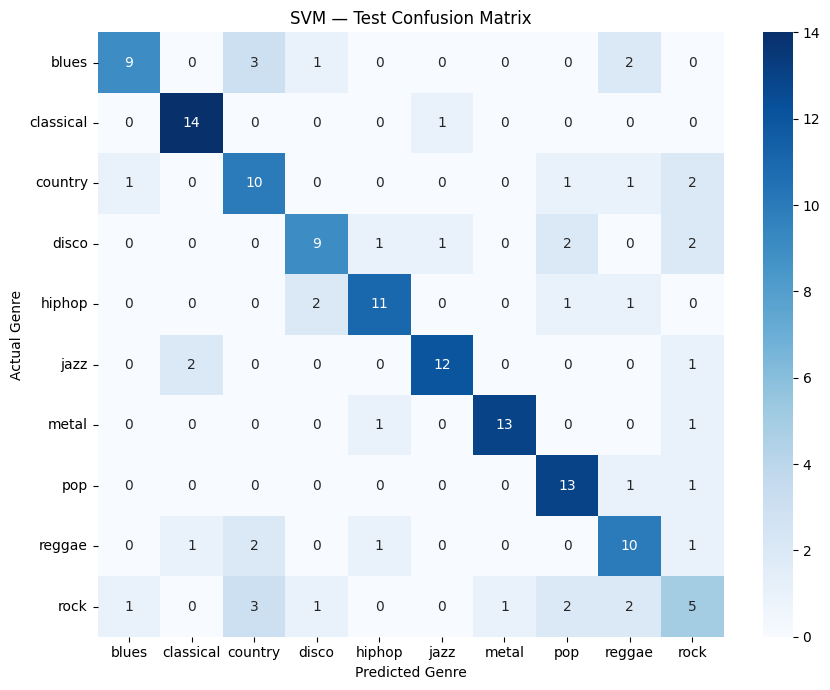

In [ ]:
test_pred_svm = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, test_pred_svm)
svm_f1 = f1_score(y_test, test_pred_svm, average="macro")

print("SVM Test Accuracy:", round(svm_accuracy, 4))
print("SVM Test Macro F1:", round(svm_f1, 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    test_pred_svm,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

cm_svm = confusion_matrix(
    y_test,
    test_pred_svm,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.title("SVM — Test Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.tight_layout()
plt.show()

In [ ]:
IMG_HEIGHT = 128
IMG_WIDTH = 256
N_MELS = 128
HOP_LENGTH = 512
N_FFT = 2048

def make_spectrogram(path):
    audio, sr = load_audio(path)

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Resize time dimension to a fixed width
    mel_db = tf.image.resize(
        mel_db[..., np.newaxis],
        [IMG_HEIGHT, IMG_WIDTH]
    ).numpy()

    return mel_db.astype(np.float32)


spec_cache = {}

for path in tqdm(df_valid["filepath"], desc="Creating spectrograms"):
    try:
        spec_cache[path] = make_spectrogram(path)
    except Exception as e:
        print("Skipping spectrogram:", path, str(e))

train_df = train_df[train_df["filepath"].isin(spec_cache)].copy()
val_df = val_df[val_df["filepath"].isin(spec_cache)].copy()
test_df = test_df[test_df["filepath"].isin(spec_cache)].copy()

X_img_train = np.stack([spec_cache[p] for p in train_df["filepath"]])
X_img_val = np.stack([spec_cache[p] for p in val_df["filepath"]])
X_img_test = np.stack([spec_cache[p] for p in test_df["filepath"]])

y_img_train = train_df["label"].to_numpy()
y_img_val = val_df["label"].to_numpy()
y_img_test = test_df["label"].to_numpy()

print("CNN training shape:", X_img_train.shape)
print("CNN validation shape:", X_img_val.shape)
print("CNN test shape:", X_img_test.shape)

Creating spectrograms:   0%|          | 0/999 [00:00<?, ?it/s]

CNN training shape: (699, 128, 256, 1)
CNN validation shape: (150, 128, 256, 1)
CNN test shape: (150, 128, 256, 1)


In [ ]:
spec_mean = X_img_train.mean()
spec_std = X_img_train.std() + 1e-6

X_img_train = (X_img_train - spec_mean) / spec_std
X_img_val = (X_img_val - spec_mean) / spec_std
X_img_test = (X_img_test - spec_mean) / spec_std

print("Normalization mean:", spec_mean)
print("Normalization std:", spec_std)

Normalization mean: -42.77733
Normalization std: 15.406529


In [ ]:
num_classes = len(encoder.classes_)

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),

    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 128, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,370 (435.04 KB)

 Trainable params: 110,922 (433.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = cnn_model.fit(
    X_img_train,
    y_img_train,
    validation_data=(X_img_val, y_img_val),
    epochs=30,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 23s 261ms/step - accuracy: 0.3247 - loss: 1.8818 - val_accuracy: 0.1800 - val_loss: 2.2651 - learning_rate: 0.0010
Epoch 2/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4092 - loss: 1.6062 - val_accuracy: 0.1333 - val_loss: 2.9710 - learning_rate: 0.0010
Epoch 3/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4607 - loss: 1.4542 - val_accuracy: 0.1000 - val_loss: 4.3387 - learning_rate: 0.0010
Epoch 4/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5293 - loss: 1.3147 - val_accuracy: 0.1000 - val_loss: 5.1482 - learning_rate: 5.0000e-04
Epoch 5/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5579 - loss: 1.2562 - val_accuracy: 0.1000 - val_loss: 5.6622 - learning_rate: 5.0000e-04
Epoch 6/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5880 - loss: 1.1627 - val_accuracy: 0.1067 - val_loss: 5.9028 - learning_rate: 2.5000e-04


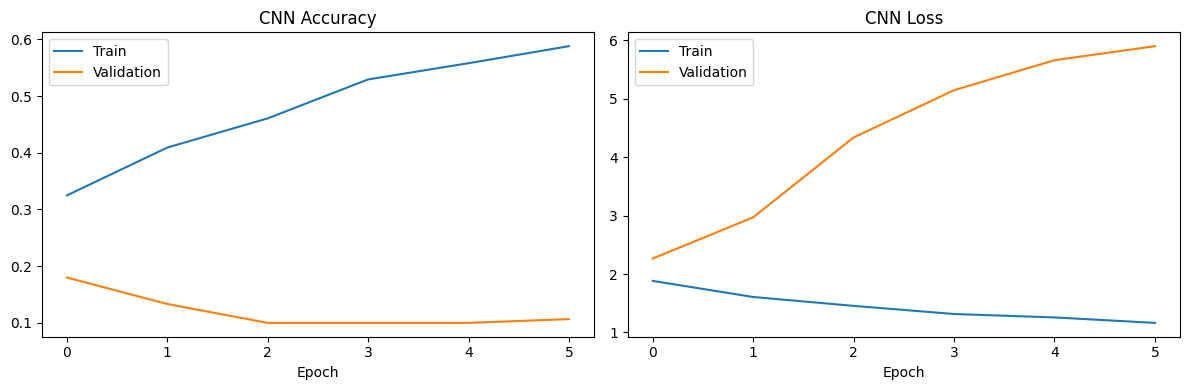

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

CNN Test Accuracy: 0.1667
CNN Test Macro F1: 0.0943

Classification Report:

              precision    recall  f1-score   support

       blues       1.00      0.07      0.12        15
   classical       0.44      0.53      0.48        15
     country       0.00      0.00      0.00        15
       disco       0.00      0.00      0.00        15
      hiphop       1.00      0.07      0.12        15
        jazz       0.00      0.00      0.00        15
       metal       0.12      1.00      0.21        15
         pop       0.00      0.00      0.00        15
      reggae       0.00      0.00      0.00        15
        rock       0.00      0.00      0.00        15

    accuracy                           0.17       150
   macro avg       0.26      0.17      0.09       150
weighted avg       0.26      0.17      0.09       150



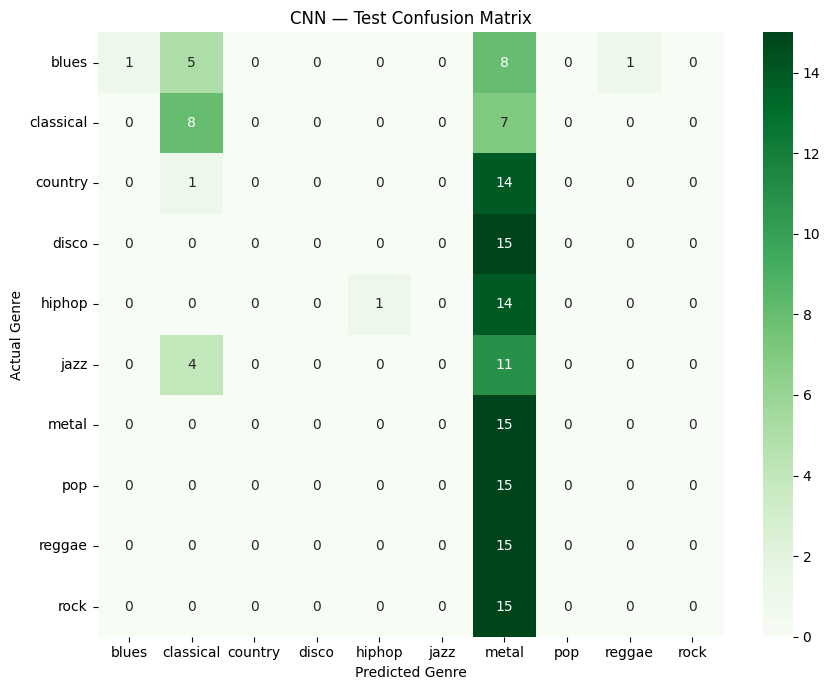

In [ ]:
cnn_probs = cnn_model.predict(X_img_test, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)

cnn_accuracy = accuracy_score(y_img_test, cnn_pred)
cnn_f1 = f1_score(y_img_test, cnn_pred, average="macro")

print("CNN Test Accuracy:", round(cnn_accuracy, 4))
print("CNN Test Macro F1:", round(cnn_f1, 4))

print("\nClassification Report:\n")
print(classification_report(
    y_img_test,
    cnn_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

cm_cnn = confusion_matrix(
    y_img_test,
    cnn_pred,
    labels=np.arange(len(encoder.classes_))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.title("CNN — Test Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.tight_layout()
plt.show()

,Model,Test Accuracy,Test Macro F1
0,SVM (MFCC + Audio Features),0.7067,0.7046
1,CNN (Mel-Spectrogram),0.1667,0.0943


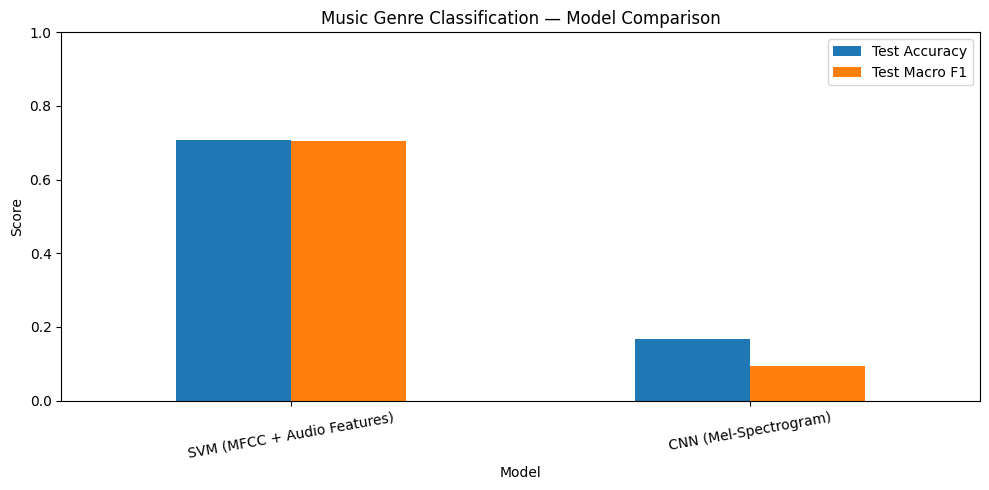

Best model based on test macro F1: SVM (MFCC + Audio Features)


In [ ]:
comparison = pd.DataFrame({
    "Model": ["SVM (MFCC + Audio Features)", "CNN (Mel-Spectrogram)"],
    "Test Accuracy": [svm_accuracy, cnn_accuracy],
    "Test Macro F1": [svm_f1, cnn_f1]
})

display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=10
)

plt.title("Music Genre Classification — Model Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

best_model_name = (
    "SVM (MFCC + Audio Features)"
    if svm_f1 >= cnn_f1
    else "CNN (Mel-Spectrogram)"
)

print("Best model based on test macro F1:", best_model_name)

In [ ]:
OUTPUT_DIR = "/content/music_genre_models"
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(
    svm_model,
    os.path.join(OUTPUT_DIR, "svm_music_genre.joblib")
)

cnn_model.save(
    os.path.join(OUTPUT_DIR, "cnn_music_genre.keras")
)

metadata = {
    "genres": encoder.classes_.tolist(),
    "sample_rate": SR,
    "duration": DURATION,
    "img_height": IMG_HEIGHT,
    "img_width": IMG_WIDTH,
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "spec_mean": float(spec_mean),
    "spec_std": float(spec_std),
    "svm_test_accuracy": float(svm_accuracy),
    "svm_test_macro_f1": float(svm_f1),
    "cnn_test_accuracy": float(cnn_accuracy),
    "cnn_test_macro_f1": float(cnn_f1)
}

with open(os.path.join(OUTPUT_DIR, "metadata.json"), "w") as f:
    json.dump(metadata, f, indent=4)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

print("Saved project files:")
print(os.listdir(OUTPUT_DIR))

Saved project files:
['svm_music_genre.joblib', 'cnn_music_genre.keras', 'model_comparison.csv', 'metadata.json']


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/music_genre_models",
    "zip",
    OUTPUT_DIR
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded_audio = files.upload()

audio_candidates = [
    name for name in uploaded_audio
    if name.lower().endswith(
        (".wav", ".mp3", ".flac", ".ogg", ".m4a")
    )
]

if not audio_candidates:
    raise ValueError("Upload a supported audio file.")

new_audio_path = "/content/" + audio_candidates[0]

print("Selected file:", new_audio_path)

Saving sample-audio-10s-8khz-mono.wav to sample-audio-10s-8khz-mono.wav
Selected file: /content/sample-audio-10s-8khz-mono.wav


In [ ]:
new_features = extract_features(new_audio_path).reshape(1, -1)

svm_probabilities = svm_model.predict_proba(new_features)[0]
svm_order = np.argsort(svm_probabilities)[::-1][:3]

print("SVM Top 3 Predictions:")

for idx in svm_order:
    print(
        f"{encoder.classes_[idx]}: "
        f"{svm_probabilities[idx] * 100:.2f}%"
    )

SVM Top 3 Predictions:
classical: 58.97%
jazz: 13.01%
blues: 7.47%


In [ ]:
new_spec = make_spectrogram(new_audio_path)

new_spec = (new_spec - spec_mean) / spec_std
new_spec = np.expand_dims(new_spec, axis=0)

cnn_probabilities = cnn_model.predict(new_spec, verbose=0)[0]
cnn_order = np.argsort(cnn_probabilities)[::-1][:3]

print("CNN Top 3 Predictions:")

for idx in cnn_order:
    print(
        f"{encoder.classes_[idx]}: "
        f"{cnn_probabilities[idx] * 100:.2f}%"
    )

predicted_index = int(np.argmax(cnn_probabilities))
print("\nCNN predicted genre:", encoder.classes_[predicted_index])

CNN Top 3 Predictions:
blues: 16.88%
classical: 15.28%
reggae: 11.97%

CNN predicted genre: blues


In [ ]:
# Final Project Summary

final_summary = pd.DataFrame({
    "Model": [
        "SVM (MFCC + Audio Features)",
        "CNN (Mel-Spectrogram)"
    ],
    "Test Accuracy": [
        svm_accuracy,
        cnn_accuracy
    ],
    "Test Macro F1": [
        svm_f1,
        cnn_f1
    ]
})

print("MUSIC GENRE CLASSIFICATION — FINAL RESULTS")
print("=" * 50)
display(final_summary.round(4))

print("\nNEW AUDIO PREDICTION")
print("=" * 50)
print("SVM prediction:", encoder.classes_[np.argmax(svm_probabilities)])
print("SVM confidence:", f"{np.max(svm_probabilities)*100:.2f}%")
print("CNN prediction:", encoder.classes_[np.argmax(cnn_probabilities)])
print("CNN confidence:", f"{np.max(cnn_probabilities)*100:.2f}%")

final_summary.to_csv(
    "/content/music_genre_final_results.csv",
    index=False
)

print("\nFinal results saved to /content/music_genre_final_results.csv")

MUSIC GENRE CLASSIFICATION — FINAL RESULTS


,Model,Test Accuracy,Test Macro F1
0,SVM (MFCC + Audio Features),0.7067,0.7046
1,CNN (Mel-Spectrogram),0.1667,0.0943



NEW AUDIO PREDICTION
SVM prediction: classical
SVM confidence: 58.97%
CNN prediction: blues
CNN confidence: 16.88%

Final results saved to /content/music_genre_final_results.csv


In [ ]:
import os

for filename in os.listdir("/content/music_genre_models"):
    print(filename)

svm_music_genre.joblib
cnn_music_genre.keras
model_comparison.csv
metadata.json


In [ ]:
from collections import Counter

print("Actual test genre distribution:")
print(Counter(encoder.inverse_transform(y_img_test)))

print("\nCNN predicted genre distribution:")
print(Counter(encoder.inverse_transform(cnn_pred)))

print("\nCNN training accuracy:",
      round(history.history["accuracy"][-1], 4))

print("CNN validation accuracy:",
      round(history.history["val_accuracy"][-1], 4))

print("CNN best validation accuracy:",
      round(max(history.history["val_accuracy"]), 4))

Actual test genre distribution:
Counter({'disco': 15, 'pop': 15, 'rock': 15, 'metal': 15, 'jazz': 15, 'reggae': 15, 'classical': 15, 'hiphop': 15, 'blues': 15, 'country': 15})

CNN predicted genre distribution:
Counter({'metal': 129, 'classical': 18, 'blues': 1, 'reggae': 1, 'hiphop': 1})

CNN training accuracy: 0.588
CNN validation accuracy: 0.1067
CNN best validation accuracy: 0.18


In [ ]:
# Rebuild CNN inputs from the cached raw spectrograms

def normalize_spectrogram(spec):
    # dB values are typically between -80 and 0
    spec = np.clip(spec, -80.0, 0.0)
    spec = (spec + 80.0) / 80.0
    return spec.astype(np.float32)

X_img_train = np.stack([
    normalize_spectrogram(spec_cache[p])
    for p in train_df["filepath"]
])

X_img_val = np.stack([
    normalize_spectrogram(spec_cache[p])
    for p in val_df["filepath"]
])

X_img_test = np.stack([
    normalize_spectrogram(spec_cache[p])
    for p in test_df["filepath"]
])

y_img_train = train_df["label"].to_numpy()
y_img_val = val_df["label"].to_numpy()
y_img_test = test_df["label"].to_numpy()

print("Train:", X_img_train.shape)
print("Validation:", X_img_val.shape)
print("Test:", X_img_test.shape)

print("Train range:", X_img_train.min(), X_img_train.max())

Train: (699, 128, 256, 1)
Validation: (150, 128, 256, 1)
Test: (150, 128, 256, 1)
Train range: 0.0 0.999979


In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1)),

    tf.keras.layers.Conv2D(
        32, 3, padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(
        64, 3, padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(
        128, 3, padding="same", activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes, activation="softmax"
    )
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 256, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 128, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 128, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 128, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,370 (435.04 KB)

 Trainable params: 110,922 (433.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = cnn_model.fit(
    X_img_train,
    y_img_train,
    validation_data=(X_img_val, y_img_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

Epoch 1/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 16s 118ms/step - accuracy: 0.3104 - loss: 1.9835 - val_accuracy: 0.1000 - val_loss: 2.3388 - learning_rate: 3.0000e-04
Epoch 2/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4177 - loss: 1.6161 - val_accuracy: 0.1000 - val_loss: 2.5060 - learning_rate: 3.0000e-04
Epoch 3/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4864 - loss: 1.4884 - val_accuracy: 0.1000 - val_loss: 2.8112 - learning_rate: 3.0000e-04
Epoch 4/40
43/44 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5457 - loss: 1.3720
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5336 - loss: 1.3651 - val_accuracy: 0.1000 - val_loss: 3.3864 - learning_rate: 3.0000e-04
Epoch 5/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5866 - loss: 1.2525 - val_accuracy: 0.1000 - val_loss: 3.9545 - learning_rate: 1.5000e-04
Epoch 6/40
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5866 - l

Improved CNN Test Accuracy: 0.1000
Improved CNN Macro F1: 0.0182

Classification Report:
              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        15
   classical       0.00      0.00      0.00        15
     country       0.00      0.00      0.00        15
       disco       0.00      0.00      0.00        15
      hiphop       0.00      0.00      0.00        15
        jazz       0.00      0.00      0.00        15
       metal       0.10      1.00      0.18        15
         pop       0.00      0.00      0.00        15
      reggae       0.00      0.00      0.00        15
        rock       0.00      0.00      0.00        15

    accuracy                           0.10       150
   macro avg       0.01      0.10      0.02       150
weighted avg       0.01      0.10      0.02       150



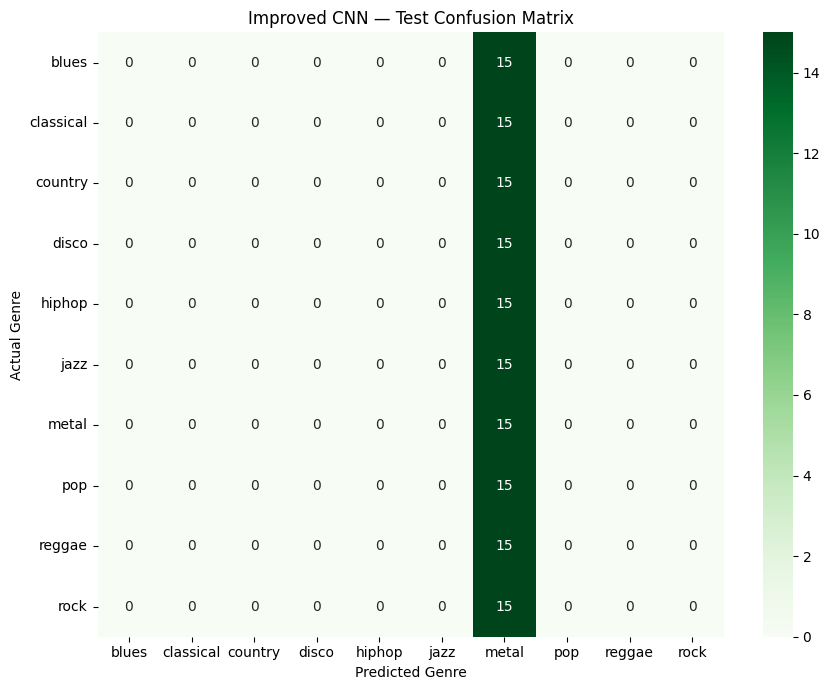


Predicted genre distribution:
Counter({'metal': 150})


In [ ]:
cnn_probs = cnn_model.predict(X_img_test, verbose=0)
cnn_pred = np.argmax(cnn_probs, axis=1)

cnn_accuracy = accuracy_score(y_img_test, cnn_pred)
cnn_f1 = f1_score(
    y_img_test, cnn_pred, average="macro"
)

print(f"Improved CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"Improved CNN Macro F1: {cnn_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_img_test,
    cnn_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

cm_cnn = confusion_matrix(
    y_img_test,
    cnn_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    cmap="Greens"
)
plt.title("Improved CNN — Test Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.tight_layout()
plt.show()

print("\nPredicted genre distribution:")
print(Counter(encoder.inverse_transform(cnn_pred)))

In [ ]:
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score

print("=== 1. INPUT SHAPES ===")
print("X_img_train:", X_img_train.shape)
print("X_img_val:  ", X_img_val.shape)
print("X_img_test: ", X_img_test.shape)

print("\n=== 2. LABEL DISTRIBUTION ===")
print("Classes:", encoder.classes_)
print("Train:", Counter(y_img_train))
print("Validation:", Counter(y_img_val))
print("Test:", Counter(y_img_test))

print("\n=== 3. SPECTROGRAM VALUE CHECK ===")
print("Train min:", np.min(X_img_train))
print("Train max:", np.max(X_img_train))
print("Train mean:", np.mean(X_img_train))
print("Train std:", np.std(X_img_train))
print("NaN values:", np.isnan(X_img_train).sum())
print("Infinite values:", np.isinf(X_img_train).sum())

print("\n=== 4. MODEL PREDICTIONS ===")
for split_name, X, y in [
    ("Train", X_img_train, y_img_train),
    ("Validation", X_img_val, y_img_val),
    ("Test", X_img_test, y_img_test)
]:
    probs = cnn_model.predict(X, verbose=0)
    preds = np.argmax(probs, axis=1)

    print(f"\n{split_name} accuracy: {accuracy_score(y, preds):.4f}")
    print("Predicted classes:", Counter(encoder.inverse_transform(preds)))
    print("Average maximum probability:", round(float(probs.max(axis=1).mean()), 4))

=== 1. INPUT SHAPES ===
X_img_train: (699, 128, 256, 1)
X_img_val:   (150, 128, 256, 1)
X_img_test:  (150, 128, 256, 1)

=== 2. LABEL DISTRIBUTION ===
Classes: ['blues' 'classical' 'country' 'disco' 'hiphop' 'jazz' 'metal' 'pop'
 'reggae' 'rock']
Train: Counter({np.int64(8): 70, np.int64(2): 70, np.int64(1): 70, np.int64(4): 70, np.int64(9): 70, np.int64(3): 70, np.int64(7): 70, np.int64(6): 70, np.int64(0): 70, np.int64(5): 69})
Validation: Counter({np.int64(5): 15, np.int64(9): 15, np.int64(6): 15, np.int64(4): 15, np.int64(7): 15, np.int64(2): 15, np.int64(0): 15, np.int64(3): 15, np.int64(8): 15, np.int64(1): 15})
Test: Counter({np.int64(3): 15, np.int64(7): 15, np.int64(9): 15, np.int64(6): 15, np.int64(5): 15, np.int64(8): 15, np.int64(1): 15, np.int64(4): 15, np.int64(0): 15, np.int64(2): 15})

=== 3. SPECTROGRAM VALUE CHECK ===
Train min: 0.0
Train max: 0.999979
Train mean: 0.4652828
Train std: 0.19258149
NaN values: 0
Infinite values: 0

=== 4. MODEL PREDICTIONS ===

Train acc

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "SVM (MFCC + Audio Features)",
        "Improved CNN (Mel-Spectrogram)"
    ],
    "Test Accuracy": [svm_accuracy, cnn_accuracy],
    "Test Macro F1": [svm_f1, cnn_f1]
})

display(comparison.round(4))

comparison.to_csv(
    "/content/music_genre_final_results.csv",
    index=False
)

cnn_model.save(
    "/content/music_genre_models/cnn_music_genre.keras"
)

# Update preprocessing metadata for future predictions
metadata_path = "/content/music_genre_models/metadata.json"

with open(metadata_path, "r") as f:
    metadata = json.load(f)

metadata["cnn_test_accuracy"] = float(cnn_accuracy)
metadata["cnn_test_macro_f1"] = float(cnn_f1)
metadata["spectrogram_normalization"] = "clip_db_minus80_to_0_then_scale_0_to_1"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Updated comparison and saved improved CNN.")

,Model,Test Accuracy,Test Macro F1
0,SVM (MFCC + Audio Features),0.7067,0.7046
1,Improved CNN (Mel-Spectrogram),0.1000,0.0182


Updated comparison and saved improved CNN.


In [ ]:
# Check the latest CNN training history
if "history" in globals():
    hist = history
elif "cnn_history" in globals():
    hist = cnn_history
else:
    hist = None

if hist is None:
    print("Training history variable not found. Check the output from your CNN training cell.")
else:
    h = hist.history

    print("Available history metrics:", list(h.keys()))

    for metric in ["loss", "accuracy", "val_loss", "val_accuracy"]:
        if metric in h:
            values = h[metric]
            print(
                f"{metric}: first={values[0]:.4f}, "
                f"last={values[-1]:.4f}, "
                f"best={min(values) if 'loss' in metric else max(values):.4f}"
            )

    print("Epochs completed:", len(h.get("loss", [])))

# Inspect average predicted probability for each class
probs = cnn_model.predict(X_img_train, verbose=0)
mean_probs = probs.mean(axis=0)

print("\nAverage predicted probability by genre:")
for genre, probability in zip(encoder.classes_, mean_probs):
    print(f"{genre:10s}: {probability:.4f}")

Available history metrics: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']
loss: first=1.9835, last=1.0967, best=1.0967
accuracy: first=0.3104, last=0.6323, best=0.6452
val_loss: first=2.3388, last=5.6889, best=2.3388
val_accuracy: first=0.1000, last=0.1000, best=0.1000
Epochs completed: 9

Average predicted probability by genre:
blues     : 0.1076
classical : 0.1210
country   : 0.0873
disco     : 0.0737
hiphop    : 0.0703
jazz      : 0.0862
metal     : 0.1715
pop       : 0.0921
reggae    : 0.0719
rock      : 0.1185


In [ ]:
import os
import numpy as np
import pandas as pd

# Verify that every audio file's folder matches its encoded label
check_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

check_df["folder_genre"] = check_df["filepath"].apply(
    lambda p: os.path.basename(os.path.dirname(p)).lower()
)

check_df["decoded_label"] = encoder.inverse_transform(
    check_df["label"].astype(int).to_numpy()
)

print("Total tracks:", len(check_df))
print("Missing audio files:", sum(not os.path.exists(p) for p in check_df["filepath"]))
print(
    "Folder/label mismatches:",
    (check_df["folder_genre"] != check_df["decoded_label"]).sum()
)

print("\nSample mapping:")
print(check_df[["filepath", "folder_genre", "label", "decoded_label", "split"]].head(15).to_string(index=False))

print("\nValidation examples by genre:")
print(
    check_df[check_df["split"] == "validation"]
    .groupby(["folder_genre", "decoded_label"])
    .size()
)

Total tracks: 999
Missing audio files: 0
Folder/label mismatches: 0

Sample mapping:
                                                         filepath folder_genre  label decoded_label split
      /content/gtzan/Data/genres_original/reggae/reggae.00023.wav       reggae      8        reggae train
    /content/gtzan/Data/genres_original/country/country.00041.wav      country      2       country train
/content/gtzan/Data/genres_original/classical/classical.00081.wav    classical      1     classical train
/content/gtzan/Data/genres_original/classical/classical.00003.wav    classical      1     classical train
      /content/gtzan/Data/genres_original/hiphop/hiphop.00056.wav       hiphop      4        hiphop train
          /content/gtzan/Data/genres_original/rock/rock.00097.wav         rock      9          rock train
        /content/gtzan/Data/genres_original/disco/disco.00013.wav        disco      3         disco train
        /content/gtzan/Data/genres_original/disco/disco.00071.wav  

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

cnn_model = models.Sequential([
    layers.Input(shape=(128, 256, 1)),

    layers.Conv2D(
        16, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),
    layers.BatchNormalization(),

    layers.Conv2D(
        32, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),
    layers.BatchNormalization(),

    layers.Conv2D(
        64, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = cnn_model.fit(
    X_img_train, y_img_train,
    validation_data=(X_img_val, y_img_val),
    epochs=35,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/35
44/44 ━━━━━━━━━━━━━━━━━━━━ 21s 215ms/step - accuracy: 0.1602 - loss: 2.3501 - val_accuracy: 0.1000 - val_loss: 2.3780 - learning_rate: 1.0000e-04
Epoch 2/35
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2518 - loss: 2.1530 - val_accuracy: 0.1000 - val_loss: 2.4005 - learning_rate: 1.0000e-04
Epoch 3/35
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3147 - loss: 2.0425 - val_accuracy: 0.1000 - val_loss: 2.4360 - learning_rate: 1.0000e-04
Epoch 4/35
41/44 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3350 - loss: 1.9776
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3419 - loss: 1.9743 - val_accuracy: 0.1000 - val_loss: 2.4797 - learning_rate: 1.0000e-04
Epoch 5/35
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3476 - loss: 1.9654 - val_accuracy: 0.1000 - val_loss: 2.5113 - learning_rate: 5.0000e-05
Epoch 6/35
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3505 - l

In [ ]:
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, classification_report

test_probs = cnn_model.predict(X_img_test, verbose=0)
test_preds = np.argmax(test_probs, axis=1)

print("CNN Test Accuracy:", round(accuracy_score(y_img_test, test_preds), 4))
print("CNN Macro F1:", round(f1_score(y_img_test, test_preds, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(
    y_img_test,
    test_preds,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

print("\nPredicted genre distribution:")
print(Counter(encoder.inverse_transform(test_preds)))

CNN Test Accuracy: 0.1
CNN Macro F1: 0.0182

Classification Report:
              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        15
   classical       0.00      0.00      0.00        15
     country       0.00      0.00      0.00        15
       disco       0.00      0.00      0.00        15
      hiphop       0.00      0.00      0.00        15
        jazz       0.00      0.00      0.00        15
       metal       0.10      1.00      0.18        15
         pop       0.00      0.00      0.00        15
      reggae       0.00      0.00      0.00        15
        rock       0.00      0.00      0.00        15

    accuracy                           0.10       150
   macro avg       0.01      0.10      0.02       150
weighted avg       0.01      0.10      0.02       150


Predicted genre distribution:
Counter({'metal': 150})


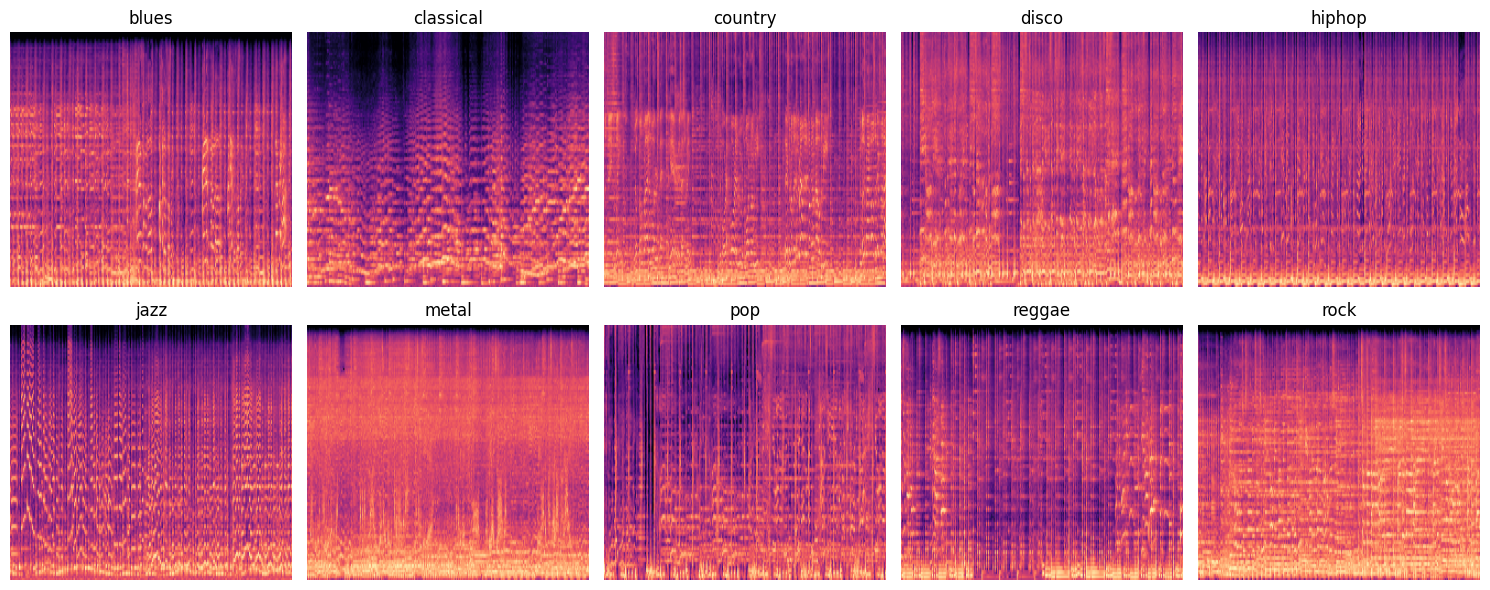

Mean pixel standard deviation across training images: 0.14929911494255066
Average per-image standard deviation: 0.1687696874141693


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Show one spectrogram from each genre
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for genre_id, ax in enumerate(axes.flat):
    indices = np.where(y_img_train == genre_id)[0]
    sample_idx = indices[0]

    ax.imshow(
        X_img_train[sample_idx, :, :, 0],
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=0,
        vmax=1
    )
    ax.set_title(encoder.classes_[genre_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Check how different the spectrograms are
print("Mean pixel standard deviation across training images:",
      float(np.mean(np.std(X_img_train, axis=0))))

print("Average per-image standard deviation:",
      float(np.mean(np.std(X_img_train, axis=(1, 2, 3)))))

In [ ]:
# Check whether CNN weights changed during training
# and inspect its output layer

print("Final layer:", cnn_model.layers[-1].name)
print("Output shape:", cnn_model.output_shape)

print("\nWeight statistics:")
for layer in cnn_model.layers:
    weights = layer.get_weights()
    if weights:
        print(
            f"{layer.name:25s}",
            "weight mean =", round(float(weights[0].mean()), 6),
            "weight std =", round(float(weights[0].std()), 6)
        )

print("\nTraining history:")
for key in ["loss", "accuracy", "val_loss", "val_accuracy"]:
    values = history.history.get(key, [])
    if values:
        print(
            f"{key:15s} first={values[0]:.4f}, "
            f"best={min(values) if 'loss' in key else max(values):.4f}, "
            f"last={values[-1]:.4f}"
        )

print("\nPrediction probabilities for 5 different training tracks:")
probs = cnn_model.predict(X_img_train[:5], verbose=0)

for i, p in enumerate(probs):
    top3 = np.argsort(p)[-3:][::-1]
    print(
        f"Track {i+1}:",
        [(encoder.classes_[j], round(float(p[j]), 3)) for j in top3]
    )

Final layer: dense_1
Output shape: (None, 10)

Weight statistics:
conv2d                    weight mean = -0.005697 weight std = 0.117777
batch_normalization       weight mean = 0.999696 weight std = 0.001153
conv2d_1                  weight mean = 0.000378 weight std = 0.06805
batch_normalization_1     weight mean = 0.999942 weight std = 0.00128
conv2d_2                  weight mean = -0.000243 weight std = 0.047965
batch_normalization_2     weight mean = 0.999718 weight std = 0.001297
dense                     weight mean = -0.001291 weight std = 0.124419
dense_1                   weight mean = 0.004187 weight std = 0.168759

Training history:
loss            first=2.3501, best=1.8844, last=1.8844
accuracy        first=0.1602, best=0.3648, last=0.3648
val_loss        first=2.3780, best=2.3780, last=2.5081
val_accuracy    first=0.1000, best=0.1133, last=0.1133

Prediction probabilities for 5 different training tracks:
Track 1: [('metal', 0.123), ('rock', 0.113), ('reggae', 0.112)]
Tra

blues: min=0.000, max=0.988, mean=0.489, std=0.176


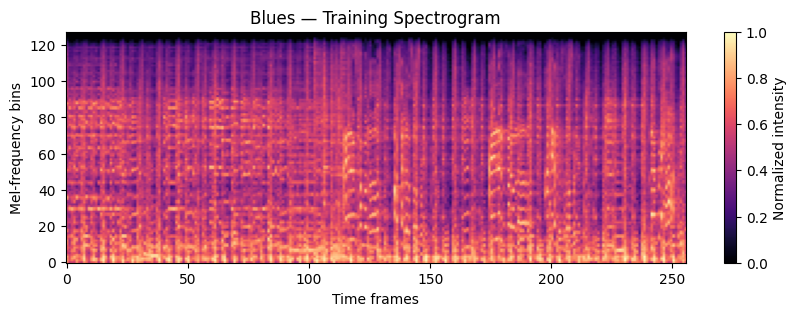

classical: min=0.000, max=0.970, mean=0.400, std=0.207


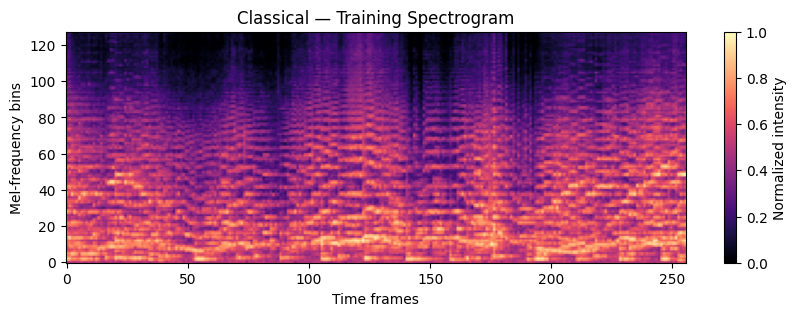

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Choose one blues track and one classical track
for genre in ["blues", "classical"]:
    idx = np.where(y_img_train == list(encoder.classes_).index(genre))[0][0]
    spec = X_img_train[idx, :, :, 0]

    print(
        f"{genre}: min={spec.min():.3f}, "
        f"max={spec.max():.3f}, "
        f"mean={spec.mean():.3f}, "
        f"std={spec.std():.3f}"
    )

    plt.figure(figsize=(10, 3))
    plt.imshow(
        spec,
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=0,
        vmax=1
    )
    plt.title(f"{genre.title()} — Training Spectrogram")
    plt.xlabel("Time frames")
    plt.ylabel("Mel-frequency bins")
    plt.colorbar(label="Normalized intensity")
    plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
import numpy as np

train_probs = cnn_model.predict(X_img_train, verbose=0)
train_preds = np.argmax(train_probs, axis=1)

print("Training accuracy:", round(accuracy_score(y_img_train, train_preds), 4))
print("Training predicted genres:")
print(Counter(encoder.inverse_transform(train_preds)))

print("\nValidation accuracy:", round(
    accuracy_score(y_img_val, np.argmax(cnn_model.predict(X_img_val, verbose=0), axis=1)), 4
))

Training accuracy: 0.1001
Training predicted genres:
Counter({'metal': 699})

Validation accuracy: 0.1


CNN Classification Report:

              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        15
   classical       0.00      0.00      0.00        15
     country       0.00      0.00      0.00        15
       disco       0.00      0.00      0.00        15
      hiphop       0.00      0.00      0.00        15
        jazz       0.00      0.00      0.00        15
       metal       0.10      1.00      0.18        15
         pop       0.00      0.00      0.00        15
      reggae       0.00      0.00      0.00        15
        rock       0.00      0.00      0.00        15

    accuracy                           0.10       150
   macro avg       0.01      0.10      0.02       150
weighted avg       0.01      0.10      0.02       150



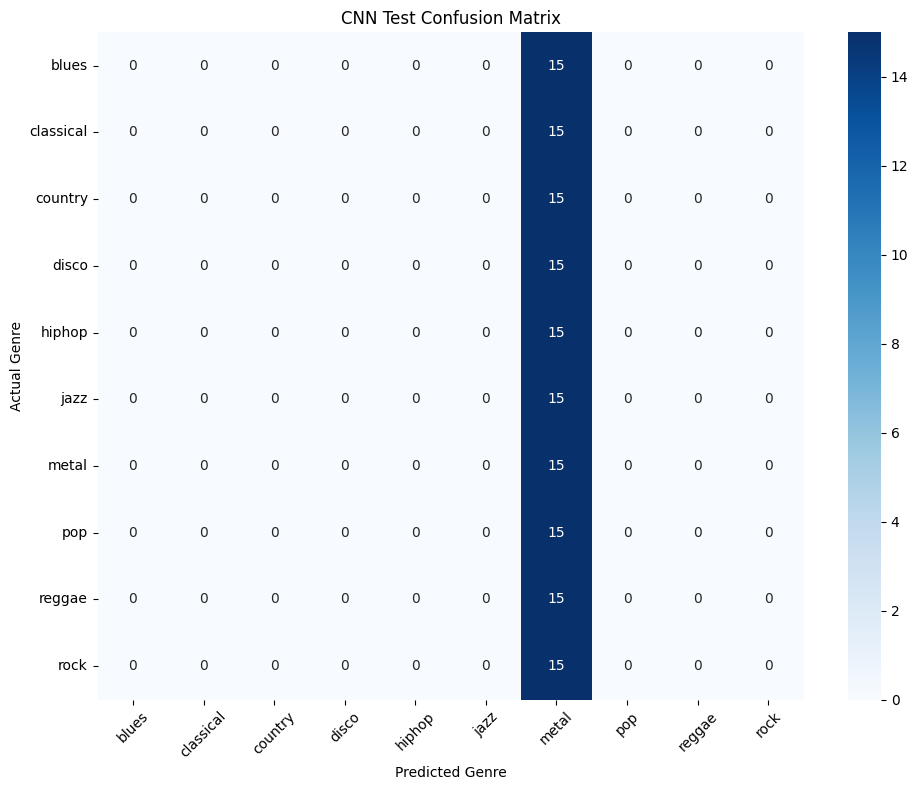

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

cnn_probs = cnn_model.predict(X_img_test, verbose=0)
cnn_preds = np.argmax(cnn_probs, axis=1)

print("CNN Classification Report:\n")
print(classification_report(
    y_img_test,
    cnn_preds,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

plt.figure(figsize=(10, 8))
sns.heatmap(
    confusion_matrix(y_img_test, cnn_preds),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)
plt.title("CNN Test Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["SVM (MFCC and audio features)", "CNN (Mel-spectrograms)"],
    "Test Accuracy": [0.7067, 0.10],
    "Macro F1-Score": [0.7046, 0.0182],
    "Status": ["Best-performing model", "Failed to learn all genres"]
})

display(results)

results.to_csv("music_genre_classification_results.csv", index=False)
print("Results saved successfully.")

,Model,Test Accuracy,Macro F1-Score,Status
0,SVM (MFCC and audio features),0.7067,0.7046,Best-performing model
1,CNN (Mel-spectrograms),0.1000,0.0182,Failed to learn all genres


Results saved successfully.


In [ ]:
import joblib
from google.colab import files

joblib.dump(svm_model, "svm_model.joblib")
joblib.dump(encoder, "genre_encoder.joblib")

files.download("svm_model.joblib")
files.download("genre_encoder.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install gradio librosa soundfile scikit-learn

In [ ]:
import gradio as gr
import librosa
import numpy as np
import os

SR = 22050
DURATION = 30
N_FFT = 2048
HOP_LENGTH = 512

def extract_audio_features(audio_path):
    y, sr = librosa.load(
        audio_path,
        sr=SR,
        mono=True,
        duration=DURATION
    )

    target_length = SR * DURATION

    if len(y) < target_length:
        y = np.pad(y, (0, target_length - len(y)))
    else:
        y = y[:target_length]

    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=20,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    chroma = librosa.feature.chroma_stft(
        y=y, sr=sr,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    centroid = librosa.feature.spectral_centroid(
        y=y, sr=sr,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    bandwidth = librosa.feature.spectral_bandwidth(
        y=y, sr=sr,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    rolloff = librosa.feature.spectral_rolloff(
        y=y, sr=sr,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    zcr = librosa.feature.zero_crossing_rate(
        y=y, frame_length=N_FFT, hop_length=HOP_LENGTH
    )

    rms = librosa.feature.rms(
        y=y, frame_length=N_FFT, hop_length=HOP_LENGTH
    )

    features = []
    features.extend(np.mean(mfcc, axis=1))
    features.extend(np.std(mfcc, axis=1))
    features.extend(np.mean(chroma, axis=1))
    features.extend(np.std(chroma, axis=1))

    for feature in [centroid, bandwidth, rolloff, zcr, rms]:
        features.append(float(np.mean(feature)))
        features.append(float(np.std(feature)))

    return np.asarray(features, dtype=np.float32).reshape(1, -1)


def predict_genre(audio_path):
    if audio_path is None:
        return "Please upload an audio file.", {}

    try:
        features = extract_audio_features(audio_path)

        expected = getattr(svm_model, "n_features_in_", features.shape[1])
        if features.shape[1] != expected:
            return (
                f"Feature mismatch: app generated {features.shape[1]} "
                f"features, but the trained model expects {expected}. "
                "The feature extraction must match your training notebook.",
                {}
            )

        predicted_id = int(svm_model.predict(features)[0])
        predicted_genre = str(
            encoder.inverse_transform([predicted_id])[0]
        ).title()

        probabilities = svm_model.predict_proba(features)[0]

        if hasattr(svm_model, "named_steps") and "svc" in svm_model.named_steps:
            class_ids = svm_model.named_steps["svc"].classes_
        else:
            class_ids = svm_model.classes_

        genre_names = encoder.inverse_transform(
            np.asarray(class_ids, dtype=int)
        )

        scores = {
            str(genre).title(): float(probability)
            for genre, probability in zip(genre_names, probabilities)
        }

        return f"Predicted music genre: {predicted_genre}", scores

    except Exception as e:
        return f"Prediction error: {type(e).__name__}: {e}", {}


demo = gr.Interface(
    fn=predict_genre,
    inputs=gr.Audio(
        type="filepath",
        label="Upload a music file"
    ),
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Label(label="Genre probability estimates", num_top_classes=5)
    ],
    title="🎵 Music Genre Classification",
    description=(
        "Upload a song to classify it into one of 10 genres: "
        "blues, classical, country, disco, hiphop, jazz, metal, pop, reggae, or rock. "
        "Powered by the trained SVM model."
    ),
    examples=None
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c80b4db06cbe49a650.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
